In [1]:
python -m pip install numpy==1.23.5 pandas==1.5.3 matplotlib seaborn scikit-learn jupyter ipywidgets joblib ipykernel

SyntaxError: invalid syntax (4126376678.py, line 1)

In [2]:
!python -m pip install numpy==1.23.5 pandas==1.5.3 matplotlib seaborn scikit-learn jupyter ipywidgets joblib ipykernel

  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\ITLAB\\anaconda3\\Lib\\site-packages\\~umpy.libs\\libscipy_openblas64_-caad452230ae4ddb57899b8b3a33c55c.dll'
Consider using the `--user` option or check the permissions.



In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import ipywidgets
import joblib

print("All libraries installed successfully!")

All libraries installed successfully!


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import ipywidgets as widgets
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
df = pd.read_csv("House Price Prediction Dataset.csv")

df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [6]:
# Dataset size
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Shape: (2000, 10)

Column Names:
Index(['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt',
       'Location', 'Condition', 'Garage', 'Price'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         2000 non-null   int64 
 1   Area       2000 non-null   int64 
 2   Bedrooms   2000 non-null   int64 
 3   Bathrooms  2000 non-null   int64 
 4   Floors     2000 non-null   int64 
 5   YearBuilt  2000 non-null   int64 
 6   Location   2000 non-null   object
 7   Condition  2000 non-null   object
 8   Garage     2000 non-null   object
 9   Price      2000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 156.4+ KB

Statistical Summary:


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [7]:
# Check missing values
print(df.isnull().sum())

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64


In [8]:
# Check missing values
print("Before Cleaning:")
print(df.isnull().sum())

# Fill missing numerical values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing text values with mode
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nAfter Cleaning:")
print(df.isnull().sum())

Before Cleaning:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

After Cleaning:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64


In [9]:
# Check duplicate rows
print("Duplicates:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

print("Dataset Shape:", df.shape)

Duplicates: 0
Dataset Shape: (2000, 10)


In [10]:
df.head(10)

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056
5,6,3944,1,2,1,1906,Urban,Poor,No,93262
6,7,3671,1,1,2,1948,Rural,Poor,Yes,448722
7,8,3419,2,4,1,1925,Suburban,Good,Yes,594893
8,9,630,2,2,1,1932,Rural,Poor,Yes,652878
9,10,2185,3,3,1,2000,Downtown,Poor,No,340375


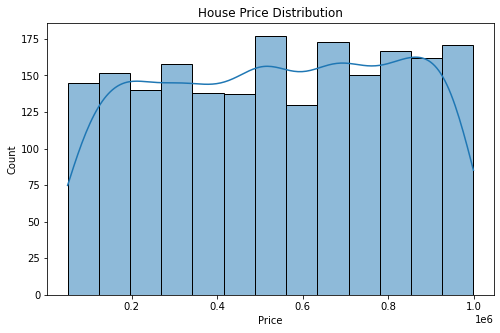

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(df["Price"], kde=True)
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

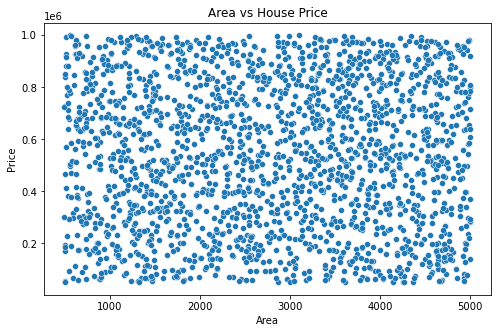

In [12]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="Area", y="Price", data=df)
plt.title("Area vs House Price")
plt.show()

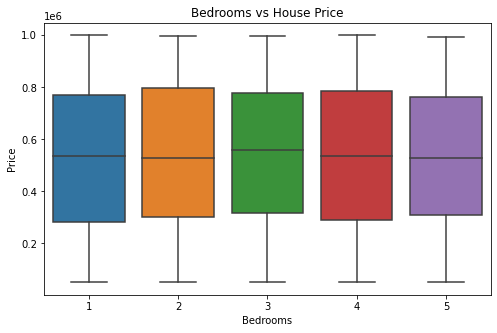

In [13]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Bedrooms", y="Price", data=df)
plt.title("Bedrooms vs House Price")
plt.show()

In [14]:
X = df.drop(columns=["Price", "Id"])
y = df["Price"]

print("Features:")
print(X.columns)

print("Target: Price")

Features:
Index(['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location',
       'Condition', 'Garage'],
      dtype='object')
Target: Price


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Separate numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include="object").columns

# Preprocessing for numerical data
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical data
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessing completed!")

Preprocessing completed!


In [18]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Price", "Id"])
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training and Testing split completed!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Training and Testing split completed!
X_train: (1600, 8)
X_test: (400, 8)


In [19]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

Preprocessing completed!


In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [21]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

Preprocessing completed!


In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [23]:
predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test_processed)
    print(name, "prediction completed!")

Linear Regression prediction completed!
Decision Tree prediction completed!
Random Forest prediction completed!


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print("\n", name)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


 Linear Regression
MAE: 245875.135
MSE: 79876699435.035
RMSE: 282624.6617601426
R2 Score: -0.0267082545414441

 Decision Tree
MAE: 332170.07
MSE: 164126331062.57
RMSE: 405125.0807621888
R2 Score: -1.1096247101020267

 Random Forest
MAE: 254587.840175
MSE: 86571527999.46388
RMSE: 294230.39951620204
R2 Score: -0.1127613313267386


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,245875.135000,7.987670e+10,282624.661760,-0.026708
1,Decision Tree,332170.070000,1.641263e+11,405125.080762,-1.109625
2,Random Forest,254587.840175,8.657153e+10,294230.399516,-0.112761


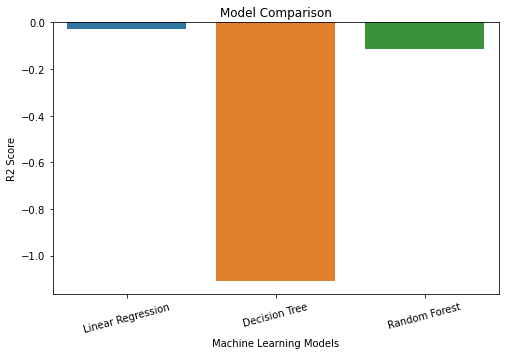

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score")
plt.title("Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.show()

In [27]:
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Selected Model:", best_model_name)

Selected Model: Linear Regression


In [28]:
import joblib

joblib.dump(
    {"model": best_model, "preprocessor": preprocessor},
    "house_price_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [32]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import joblib

# Load saved model
saved = joblib.load("house_price_model.pkl")
best_model = saved["model"]
preprocessor = saved["preprocessor"]

# Input fields
area = widgets.FloatText(description="Area:")
bedrooms = widgets.IntText(description="Bedrooms:")
bathrooms = widgets.IntText(description="Bathrooms:")
floors = widgets.IntText(description="Floors:")
year_built = widgets.IntText(description="Year Built:")
location = widgets.Text(description="Location:")
condition = widgets.Text(description="Condition:")
garage = widgets.IntText(description="Garage:")

button = widgets.Button(
    description="Predict Price",
    button_style="success"
)
output = widgets.Output()

def predict_price(b):
    with output:
        clear_output()

        # Create input using the model's feature columns
        input_data = pd.DataFrame([{
            "Area": area.value,
            "Bedrooms": bedrooms.value,
            "Bathrooms": bathrooms.value,
            "Floors": floors.value,
            "YearBuilt": year_built.value,
            "Location": location.value,
            "Condition": condition.value,
            "Garage": garage.value
        }])

        try:
            input_data = input_data[X.columns]
            processed_data = preprocessor.transform(input_data)
            prediction = best_model.predict(processed_data)[0]

            print(f"Predicted House Price: {prediction:,.2f}")
        except Exception as e:
            print("Error:", e)

button.on_click(predict_price)

display(
    area, bedrooms, bathrooms, floors,
    year_built, location, condition, garage,
    button, output
)

FloatText(value=0.0, description='Area:')

IntText(value=0, description='Bedrooms:')

IntText(value=0, description='Bathrooms:')

IntText(value=0, description='Floors:')

IntText(value=0, description='Year Built:')

Text(value='', description='Location:')

Text(value='', description='Condition:')

IntText(value=0, description='Garage:')

Button(button_style='success', description='Predict Price', style=ButtonStyle())

Output()

In [34]:
# Test the saved model
import joblib
import pandas as pd

saved = joblib.load("house_price_model.pkl")
model = saved["model"]
preprocessor = saved["preprocessor"]

# Use one row from test data
sample = X_test.iloc[[0]]

# Predict house price
sample_processed = preprocessor.transform(sample)
predicted_price = model.predict(sample_processed)[0]

print("Actual Price:", y_test.iloc[0])
print("Predicted Price:", predicted_price)

Actual Price: 514764
Predicted Price: 499712.0
